# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** 

 - Устройство: локальный ПК, NVIDIA GeForce RTX 5070 Ti Laptop GPU (12 GB VRAM)
 - Модель: DeepPavlov/rubert-base-cased (https://huggingface.co/DeepPavlov/rubert-base-cased, revision 4036cab694767a299f2b9e6492909664d9414229, лицензия в карточке None, проект DeepPavlov - Apache-2.0)  
 - Датасет: Babelscape/wikineural, русские сплиты train_ru/val_ru/test_ru (https://huggingface.co/datasets/Babelscape/wikineural, лицензия CC BY-NC-SA 4.0).
 - Бонусы: не выполнялись (BONUS_TASKS = set()) 
 - Источники: Gemini Web-Based (для уточнения сигнатур функций, работы методов и классов и тд)
 - Нерешённые задачи: нет

In [67]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\Ilya\ITMO\3course\dl\hw2_students\.venv\Scripts\python.exe: No module named pip


In [68]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [69]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [70]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [71]:
MODEL_ID = 'DeepPavlov/rubert-base-cased'   # ваш код: id модели на Hugging Face Hub
REVISION = '4036cab694767a299f2b9e6492909664d9414229'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [72]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    DeepPavlov/rubert-base-cased
revision: 4036cab694767a299f2b9e6492909664d9414229
license:  None
language: ['ru']
updated:  2021-11-23 08:03:04+00:00
weights:  {'pytorch_model.bin': '681 MB'}
BertTokenizer vocab size 119547
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** 

Выбрал DeepPavlov/rubert-base-cased: она предобучена на русской Википедии и новостях (совпадает с доменом WikiNEuRal) и сохраняет регистр. По размеру она оптимальна по качеству и быстрым дообучением на GPU; в карточке HF лицензия не указана, но сам проект DeepPavlov распространяется под открытой лицензией Apache-2.0. По сравнению с rubert-tiny2, которая должна быть сильно быстрее, rubert-base-cased глубже и точнее; в сравнении с мультиязычной xlm-roberta-base одноязычный RuBERT компактнее, быстрее и не использует ёмкость словаря и весов на сотню других языков.

Без фиксации revision через полгода ветка main может обновиться: перезалитые веса нарушат воспроизводимость метрик, изменения в токенизаторе или конфиге способны поменять разбиение на сабворды/токены.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [73]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 39416.01it/s]

{'model_type': 'bert', 'vocab_size': 119547, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [74]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    result = {}
    base = model.base_model

    result['embeddings'] = sum(p.numel() for p in base.embeddings.parameters())
    result['layers'] = [sum(p.numel() for p in layer.parameters()) for layer in base.encoder.layer]
    result['encoder'] = sum(result['layers'])
    result['head'] = sum(p.numel() for p in model.classifier.parameters())
    result['other'] = sum(p.numel() for n, p in model.named_parameters()) - result['embeddings'] - result['encoder'] - result['head']
    
    return result

In [75]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,208,384   52.0%
encoder       85,054,464   48.0%
head               5,383    0.0%
other                  0    0.0%
total        177,268,231
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [76]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]

enc = tokenizer(demo_texts, is_split_into_words=True, return_tensors='pt', padding=True)

with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids', enc['input_ids'].shape)
print('attention_mask', enc['attention_mask'].shape)
print('hidden_states per layer:', [h.shape for h in out.hidden_states])
print('logits', out.logits.shape)

input_ids torch.Size([2, 10])
attention_mask torch.Size([2, 10])
hidden_states per layer: [torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768]), torch.Size([2, 10, 768])]
logits torch.Size([2, 10, 7])


In [77]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 29.6 ms на NVIDIA GeForce RTX 5070 Ti Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** 

Входные тензоры input_ids и attention_mask формы (2, 10) проходят через блок эмбеддингов и получают форму (2, 10, 768). Далее эта форма сохраняется после каждого слоя энкодера, а на выходе линейная голова переводит представления каждого токена в логиты формы (2, 10, 7).

Больше всего параметров содержит блок embeddings, так как ему необходимо хранить таблицу весов для всего большого словаря сабвордов и сопоставлять каждому токену вектор представления.

Токены обмениваются информацией в слоях энкодера, тогда как в блоке эмбеддингов и в финальной голове классификации каждый токен обрабатывается независимо от остальных.

Длина T в логитах больше числа исходных слов, поскольку токенизатор разбивает часть слов на несколько сабвордов, добавляет служебные токены и дополняет более короткие предложения в батче токенами паддинга.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [78]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [79]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
_train = load_dataset(DATASET_ID, DATASET_CONFIG, split='train_ru')
_test = load_dataset(DATASET_ID, DATASET_CONFIG, split='test_ru')
_val = load_dataset(DATASET_ID, DATASET_CONFIG, split='val_ru')
raw = DatasetDict({'train': _train, 'test': _test, 'validation': _val})
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

train (92320 предл.): {'LOC': 71090, 'PER': 33282, 'MISC': 23594, 'ORG': 20236} | спан mean=1.31, max=24 | предл. mean=19.6, max=256


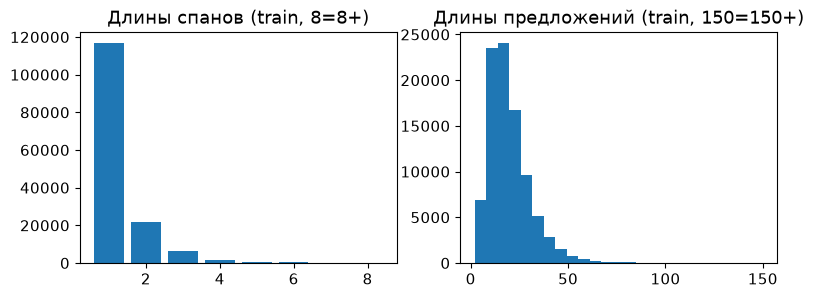

validation (11540 предл.): {'ORG': 2710, 'LOC': 8851, 'MISC': 2642, 'PER': 4007} | спан mean=1.32, max=10 | предл. mean=18.8, max=107
test (11580 предл.): {'LOC': 8596, 'PER': 3489, 'MISC': 2962, 'ORG': 3051} | спан mean=1.36, max=13 | предл. mean=18.8, max=124


In [80]:
from seqeval.metrics.sequence_labeling import get_entities

for split in ['train', 'validation', 'test']:
    cnt = collections.Counter()
    span_lens, sent_lens = [], []
    for ex in raw[split]:
        sent_lens.append(len(ex['tokens']))
        for ent_type, s, e in get_entities([LABEL_NAMES[i] for i in ex['ner_tags']]):
            cnt[ent_type] += 1
            span_lens.append(e - s + 1)
    print(f'{split} ({len(raw[split])} предл.): {dict(cnt)} | '
            f'спан mean={np.mean(span_lens):.2f}, max={max(span_lens)} | '
            f'предл. mean={np.mean(sent_lens):.1f}, max={max(sent_lens)}')
    if split == 'train':
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
        ax1.hist([min(x, 8) for x in span_lens], bins=range(1, 10), align='left', rwidth=0.8)
        ax1.set_title('Длины спанов (train, 8=8+)')
        ax2.hist([min(x, 150) for x in sent_lens], bins=25)
        ax2.set_title('Длины предложений (train, 150=150+)')
        plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** 

Взял русскую часть датасета wikineural (предложения из Википедии, лицензия CC BY-NC-SA 4.0), размеченная автоматически на основе гиперссылок Википедии и базы знаний BabelNet/Wikidata. В датасете 4 типа сущностей: в train - LOC: 71090, PER: 33282, MISC: 23594, ORG: 20236; в validation - LOC: 8851, PER: 4007, ORG: 2710, MISC: 2642; в test - LOC: 8596, PER: 3489, ORG: 3051, MISC: 2962, при этом LOC составляет почти половину, а самыми редкими являются ORG и MISC. Средняя длина спанов небольшая, но бывают выбросы вплоть до 24; предложения в среднем короткие, но хвосты длинных предложений будут обрезаться по MAX_LENGTH. Кроме того, автоматическая разметка вносит шум (пропущенные сущности без ссылок).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [81]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    i = 0
    while i < len(tags):
        if tags[i] != 'O':
            start = i
            label = tags[i][2:]
            i += 1
            while i < len(tags) and tags[i].startswith('I-') and tags[i][2:] == label:
                i += 1
            spans.append((start, i, label))
        else:
            i += 1
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    bio = ['O'] * n_words
    for start, end, label in spans:
        bio[start] = f'B-{label}'
        for i in range(start + 1, end):
            bio[i] = f'I-{label}'
    return bio


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    lbls = []
    prev_wid = None

    for i in range(len(word_ids)):
        wid = word_ids[i]
        if wid is None:
            lbls.append(-100)
        elif wid != prev_wid:
            lbls.append(word_labels[wid])
            prev_wid = wid
        else:
            if b_to_i is None:
                lbls.append(-100)
            else:
                lbls.append(b_to_i.get(word_labels[wid], word_labels[wid]))

    return lbls


In [82]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [83]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
cnt = {}

Path('data').mkdir(exist_ok=True)
for split in ['train', 'validation', 'test']:
    cnt[split] = 0

    with open(f'data/{split}_spans.jsonl', 'w', encoding='utf-8') as f:
        for ex in raw[split]:
            json.dump({'tokens': ex['tokens'], 'spans': bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])}, f, ensure_ascii=False)
            f.write('\n')

    with open(f'data/{split}_spans.jsonl', 'r', encoding='utf-8') as f:
        for orig_ex, line in zip(raw[split], f):
            ex = json.loads(line)
            ex['spans'] = [tuple(span) for span in ex['spans']]

            bio = spans_to_bio(ex['spans'], len(ex['tokens']))
            assert bio_to_spans(bio) == ex['spans']

            if bio != [LABEL_NAMES[i] for i in orig_ex['ner_tags']]:
                cnt[split] += 1

print(f'несовпадений BIO и исходных тегов: {cnt}')

несовпадений BIO и исходных тегов: {'train': 3210, 'validation': 393, 'test': 464}


In [84]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map: 100%|██████████| 11580/11580 [00:00<00:00, 38099.59 examples/s]


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 92250 предложений, обрезано по MAX_LENGTH 66, слов без сабвордов или за обрезкой 1880
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Надь                3  B-LOC
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** 

Метка ставится только на первый сабворд, чтобы каждое слово вносило одинаковый вклад в обучение (длинные слова, разбитые на много сабвордов, не получали лишний вес) и чтобы обучение совпадало с инференсом, где тег слова берётся с первого сабворда. Значение -100 - это ignore_index: такие позиции полностью исключаются из расчёта кросс-энтропии и нормировки лосса.

На полном train по MAX_LENGTH = 128 обрезано 66 предложений, слов без сабвордов или за обрезкой - 1880. На инференсе они получают O, что слегка снижает recall на хвостах длинных предложений, но из-за малой доли влияние на метрику невелико.

Датасет уже размечен по словам в BIO (вложенных/пересекающихся спанов и расхождения токенизации нет), все спаны восстановились через jsonl без потерь, однако нашлись предложения с битым BIO (I-X без B-X или смена типа на I-), но их часть в пределах 5%.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [85]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [86]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    cnt = {}
    for tokens, tags in zip(tokens_list, tags_list):
        for token, tag in zip(tokens, tags):
            if token not in cnt:
                cnt[token] = {}
                cnt[token][tag] = 1
            else:
                if tag not in cnt[token]:
                    cnt[token][tag] = 1
                else:
                    cnt[token][tag] += 1
    result = {}
    for token in cnt:
        result[token] = max(cnt[token], key=cnt[token].get)

    return result


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [87]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

maj_predictor = fit_majority_tagger(data['train']['tokens'], [[LABEL_NAMES[tag] for tag in tags] for tags in data['train']['ner_tags']])

baseline = {
    'majority': entity_scores(val_gold, [predict_majority(maj_predictor, tokens) for tokens in val_tokens]),
    'random_head': entity_scores(val_gold, predict_word_tags(make_model(), val_tokens)),
}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 43337.77it/s]


In [88]:
baseline

{'majority': {'f1_micro': np.float64(0.5843722774656773),
  'f1_macro': np.float64(0.5089478842707436),
  'precision': np.float64(0.6450885454666048),
  'recall': np.float64(0.5341021416803954)},
 'random_head': {'f1_micro': np.float64(0.02264981911602789),
  'f1_macro': np.float64(0.021789890720976004),
  'precision': np.float64(0.012859630583297364),
  'recall': np.float64(0.09489291598023064)}}

**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

На датасете словарный бейзлайн набрал f1_micro = 0.584 (f1_macro = 0.509) при precision = 0.645 и recall = 0.534. Довольно высокий для простого словаря результат можно объяснить короткими спанами, большим объёмом train и преобладанием повторяющихся однословных LOC из Википедии; при этом потолок всё равно ограничен незнакомыми словами, падежными формами, перевесом тега O и разрывом границ многословных сущностей без контекста.

Энкодер со случайной головой даёт f1_micro = 0.023 (f1_macro = 0.022, precision = 0.013, recall = 0.095), так как, несмотря на предобученные представления, случайный слой Linear(768, 9) не знает отображения признаков в BIO-теги и предсказывает шум по всем классам.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [89]:
LR = 2e-5          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_steps = max(1, total_steps // 10)

    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad = False

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=lr,
        logging_steps=log_steps,
        eval_strategy="steps",
        eval_steps=log_steps,
        save_strategy="no",
        warmup_steps=int(0.1 * total_steps),
        weight_decay=0.01,
        report_to="none",
        seed=SEED,
        bf16=(device.type == 'cuda'),
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tok,
        data_collator=DataCollatorForTokenClassification(tok),
    )

    start_time = time.time()
    trainer.train()
    elapsed_time = time.time() - start_time

    return trainer.state.log_history, elapsed_time

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 22186.13it/s]


{'loss': '0.2792', 'grad_norm': '1.471', 'learning_rate': '1.998e-05', 'epoch': '0.2998'}
{'eval_loss': '0.05878', 'eval_runtime': '4.699', 'eval_samples_per_second': '2456', 'eval_steps_per_second': '76.83', 'epoch': '0.2998'}
{'loss': '0.05238', 'grad_norm': '1.504', 'learning_rate': '1.778e-05', 'epoch': '0.5997'}
{'eval_loss': '0.04709', 'eval_runtime': '4.74', 'eval_samples_per_second': '2434', 'eval_steps_per_second': '76.16', 'epoch': '0.5997'}
{'loss': '0.04579', 'grad_norm': '0.5023', 'learning_rate': '1.556e-05', 'epoch': '0.8995'}
{'eval_loss': '0.04045', 'eval_runtime': '6.236', 'eval_samples_per_second': '1851', 'eval_steps_per_second': '57.89', 'epoch': '0.8995'}
{'loss': '0.03584', 'grad_norm': '0.6698', 'learning_rate': '1.334e-05', 'epoch': '1.199'}
{'eval_loss': '0.04137', 'eval_runtime': '4.954', 'eval_samples_per_second': '2329', 'eval_steps_per_second': '72.87', 'epoch': '1.199'}
{'loss': '0.02926', 'grad_norm': '0.6059', 'learning_rate': '1.112e-05', 'epoch': '1.4

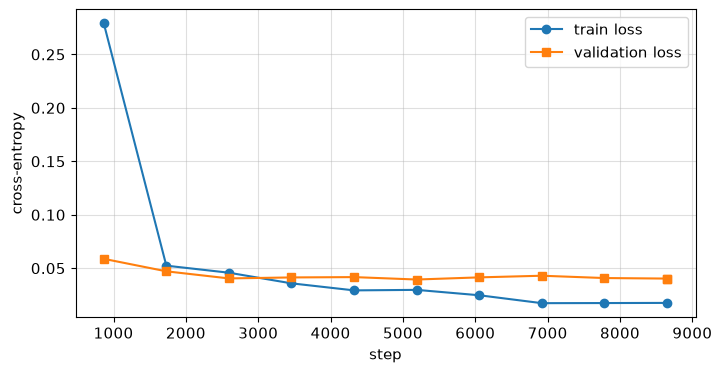

In [90]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** 

Выбраны стандартные гиперпараметры для дообучения: LR = 2e-5 (чтобы адаптировать веса без разрушения предобученных представлений), BATCH_SIZE = 32, 3 эпохи, линейный warmup на 10% шагов, weight_decay = 0.01 и bf16=True (тк у меня RTX 5070 Ti).

По кривым видно, что train loss стабильно падает, а eval_loss быстро снижается за 1-ю эпоху, достигает минимума во 2-й эпохе и далее выходит на плато, поэтому больше 3 эпох не требуется. Обучение на полном train (92 320 предл., 3 эпохи) заняло ~10 мин на RTX 5070 Ti (Laptop).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [91]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp, fp, fn = 0, 0, 0
    for g, p in zip(gold, pred):
        for g_tag, p_tag in zip(g, p):
            if g_tag != 'O' and g_tag == p_tag:
                tp += 1
            else:
                if g_tag != 'O':
                    fn += 1
                if p_tag != 'O':
                    fp += 1
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn > 0 else 0.0

In [92]:
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]

In [93]:
val_pred = predict_word_tags(model, val_tokens)

print(classification_report(val_gold, val_pred, zero_division=0))

print(f'tokenized validation micro-F1: {token_f1(val_gold, val_pred):.4f}')

              precision    recall  f1-score   support

         LOC       0.95      0.96      0.95      8851
        MISC       0.81      0.83      0.82      2642
         ORG       0.84      0.86      0.85      2710
         PER       0.94      0.94      0.94      4007

   micro avg       0.91      0.92      0.92     18210
   macro avg       0.89      0.90      0.89     18210
weighted avg       0.91      0.92      0.92     18210

tokenized validation micro-F1: 0.9197


In [94]:
test_pred = predict_word_tags(model, test_tokens)

print(classification_report(test_gold, test_pred, zero_division=0))

print(f'tokenized test micro-F1: {token_f1(test_gold, test_pred):.4f}')

              precision    recall  f1-score   support

         LOC       0.95      0.95      0.95      8596
        MISC       0.84      0.84      0.84      2962
         ORG       0.83      0.87      0.85      3051
         PER       0.93      0.94      0.93      3489

   micro avg       0.91      0.92      0.91     18098
   macro avg       0.89      0.90      0.89     18098
weighted avg       0.91      0.92      0.91     18098

tokenized test micro-F1: 0.9195


In [95]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_report = classification_report(test_gold, test_pred, zero_division=0, output_dict=True)

final = {
    **entity_scores(test_gold, test_pred),
    'token_f1': token_f1(test_gold, test_pred),
    'per_type': {t: test_report[t] for t in ENTITY_TYPES if t in test_report},
}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** 

Хуже всего распознаются MISC и ORG, в отличие от LOC и PER. Эти типы реже встречаются в датасете, имеют более разнообразную и длинную структуру и вероятно сильнее подвержены шуму автоматической разметки. Из-за дисбаланса классов micro F1 выше macro F1: в micro почти половину веса даёт частый и точный LOC, тогда как macro усредняет все 4 типа с равным весом и проявляет просадку на MISC и ORG.

Токенный F1 выше сущностного micro F1, потому что seqeval строже и не засчитывает частично угаданные многословные спаны (штрафуя сразу в FP и FN), а token_f1 даёт частичный зачёт по словам; разница небольщая из-за преобладания коротких спанов. Для пользователя NER ближе сущностный F1, так как на практике нужно извлечь полную сущность с точными границами.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [96]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    ans = []
    for g in gold_spans:
        overlaps = [p for p in pred_spans if g[0] < p[1] and g[1] > p[0]]
        if not overlaps:
            ans.append(('missed', g, None))
        else:
            if g in overlaps:
                ans.append(('correct', g, g))
            else:
                p = None
                seen = False
                for p in overlaps:
                    if g[2] == p[2]:
                        ans.append(('boundary', g, p))
                        seen = True
                        break
                if not seen:
                    ans.append(('type', g, p))
    for p in pred_spans:
        if not any(p[0] < g[1] and p[1] > g[0] for g in gold_spans):
            ans.append(('spurious', None, p))
    return ans

In [97]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

num = 3

errors = {c: 0 for c in ERROR_CATEGORIES}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров
examples = {c: [] for c in ERROR_CATEGORIES if c != 'correct'}

for words, g, p in zip(val_tokens, val_gold, val_pred):
    for cat, gs, ps in categorize_errors(bio_to_spans(g), bio_to_spans(p)):
        errors[cat] += 1
        if cat != 'correct' and len(examples[cat]) < num:
            examples[cat].append((words, gs, ps))

total_err = sum(v for k, v in errors.items() if k != 'correct')
print('counts:', errors)
print('error shares:', {k: f'{errors[k]/total_err}' for k in examples})

for cat, items in examples.items():
    print(f'\n{cat}:')
    for words, gs, ps in items:
        g_str = f"{' '.join(words[gs[0]:gs[1]])} ({gs[2]})" if gs else None
        p_str = f"{' '.join(words[ps[0]:ps[1]])} ({ps[2]})" if ps else None
        print(' ', ' '.join(words))
        print(f'   gold: {g_str} | pred: {p_str}')

counts: {'correct': 16766, 'boundary': 432, 'type': 773, 'missed': 239, 'spurious': 389}
error shares: {'boundary': '0.23567921440261866', 'type': '0.4217130387343153', 'missed': '0.1303873431533006', 'spurious': '0.21222040370976542'}

boundary:
  Вокруг щита воротник Древнейшего и благороднейшего ордена Чертополоха , со знаком Св .
   gold: ордена Чертополоха (ORG) | pred: Чертополоха (ORG)
  Позднее , в 2001 г. , он вновь возьмётся за театральную роль в хите лондонского Вест-Энда " « Кошка на раскалённой крыше » " Теннесси Уильямса .
   gold: Кошка на раскалённой крыше » (MISC) | pred: « Кошка на раскалённой крыше » (MISC)
  В 1962 - 1966 годах был профессором микробиологии и заведующим отдела микробиологии медицинской школы Университета Питтсбурга ( Питтсбург ) , продолжая работать экспертом в ВОЗ .
   gold: Университета (LOC) | pred: Университета Питтсбурга (LOC)

type:
  С 1979 года на Украине лесосплав на реках запрещен , что закреплено в Водном кодексе Украины ( 1995 ) , ст .
 

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** 

На полном validation самая частая категория ошибок - type. В boundary расходятся края многословных названий и кавычки, в type путаются смежные классы, а в missed и spurious часто попадают термины и спорные сущности.

Значительная часть показанных ошибок - это ошибки самой автоматической разметки датасета, а не модели: например, в boundary в gold потеряна открывающая кавычка (Кошка на раскалённой крыше ») и обрезан
топоним (Университета вместо Университета Питтсбурга); в type геральдический лев помечен как PER, а персонаж Смерть - как MISC (модель верно предсказала PER); в missed семейство растений Маревые и
единица массы Да ошибочно размечены как LOC; в spurious модель верно нашла реальный город Измит и роман Троецарствие, пропущенные в gold.

Чтобы уменьшить самую частую категорию type, в первую очередь стоит очистить шумную разметку (особенно границы между MISC, ORG и PER) или дообучить модель на более чистом вручную размеченном
корпусе.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [98]:
ABLATION = 'freeze'

set_seed(SEED)
model_ab = make_model()
_, ab_sec = train_ner(model_ab, tokenized['train'], tokenized['validation'], freeze_encoder=True, out_dir='runs/ablation')
ab_pred = predict_word_tags(model_ab, val_tokens)

ablation = {
    'type': ABLATION,
    'full': {
        **entity_scores(val_gold, val_pred),
        'time_sec': train_seconds,
        'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad),
    },
    'freeze': {
        **entity_scores(val_gold, ab_pred),
        'time_sec': ab_sec,
        'trainable_params': sum(p.numel() for p in model_ab.parameters() if p.requires_grad),
    },
}

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 28185.22it/s]


{'loss': '1.733', 'grad_norm': '2.876', 'learning_rate': '1.998e-05', 'epoch': '0.2998'}
{'eval_loss': '0.8381', 'eval_runtime': '5.026', 'eval_samples_per_second': '2296', 'eval_steps_per_second': '71.83', 'epoch': '0.2998'}
{'loss': '0.5431', 'grad_norm': '0.4719', 'learning_rate': '1.778e-05', 'epoch': '0.5997'}
{'eval_loss': '0.4092', 'eval_runtime': '5.215', 'eval_samples_per_second': '2213', 'eval_steps_per_second': '69.22', 'epoch': '0.5997'}
{'loss': '0.3877', 'grad_norm': '0.3646', 'learning_rate': '1.556e-05', 'epoch': '0.8995'}
{'eval_loss': '0.3472', 'eval_runtime': '5.135', 'eval_samples_per_second': '2247', 'eval_steps_per_second': '70.31', 'epoch': '0.8995'}
{'loss': '0.3386', 'grad_norm': '0.2963', 'learning_rate': '1.334e-05', 'epoch': '1.199'}
{'eval_loss': '0.307', 'eval_runtime': '5.011', 'eval_samples_per_second': '2303', 'eval_steps_per_second': '72.04', 'epoch': '1.199'}
{'loss': '0.3035', 'grad_norm': '0.2402', 'learning_rate': '1.112e-05', 'epoch': '1.499'}
{'e

In [99]:
ablation

{'type': 'freeze',
 'full': {'f1_micro': np.float64(0.9163751639702667),
  'f1_macro': np.float64(0.8917476983293373),
  'precision': np.float64(0.9120879120879121),
  'recall': np.float64(0.9207029104887424),
  'time_sec': 579.8525831699371,
  'trainable_params': 177269769},
 'freeze': {'f1_micro': np.float64(0.5237732852463356),
  'f1_macro': np.float64(0.339497023771004),
  'precision': np.float64(0.6588695579788563),
  'recall': np.float64(0.43465129049972545),
  'time_sec': 219.7009630203247,
  'trainable_params': 6921}}

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** 

При заморозке энкодера число обучаемых параметров уменьшилось с 177269769 до 6921, а время обучения сократилось в 2.6 раза. Однако качество резко просело: на validation f1_micro упал с 0.916 до 0.524, а f1_macro - с 0.892 до 0.339 (хуже даже словарного бейзлайна 0.584).

Одной линейной головы без адаптации слоёв энкодера недостаточно, чтобы перестроить общие признаки под точные границы BIO-спанов и редкие классы (ORG, MISC).

Следующим шагом для более надёжного вывода стоит подобрать повышенный LR (например, 1e-3) для замороженного варианта и проверить частичную разморозку верхних 2-4 слоёв энкодера.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** 

Дообучение DeepPavlov/rubert-base-cased на полном русскоязычном Babelscape/wikineural сработало довольно отлично: f1_micro на test достиг 0.914 (f1_macro = 0.895, token_f1 = 0.920), уверенно превзойдя словарный бейзлайн (f1_micro = 0.584) и случайную голову (0.023). Лучше всего модель выделяет частые LOC (0.954) и PER (0.935), тогда как более редкие и разнообразные ORG (0.850) и MISC (0.840) заметно отстают. Абляция freeze показала, что без дообучения самого энкодера ускорение в 2.6 раза не оправдывает провал качества.

Главным ограничением оказалась не архитектура и не бюджет, а шум автоматической разметки: неканоничные BIO-последовательности и доля ложных меток в validation, из-за чего основной категорией ошибок стал type, а часть missed и spurious фактически является ошибками gold-разметки.

Дополнительно длина входа ограничена MAX_LENGTH = 128, что практически не сказалось на метриках. Дальше имеет смысл оценить модель на чистом вручную размеченном русском корпусе, частичную заморозку/разморозку слоёв, а также сравнить с более лёгким rubert-tiny2 по соотношению скорость/качество.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [100]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "DeepPavlov/rubert-base-cased", "revision": "4036cab694767a299f2b9e6492909664d9414229", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 177269769, "ablation": {"type": "freeze", "full": {"f1_micro": 0.9163751639702667, "f1_macro": 0.8917476983293373, "precision": 0.9120879120879121, "recall": 0.9207029104887424, "time_sec": 579.8525831699371, "trainable_params": 177269769}, "freeze": {"f1_micro": 0.5237732852463356, "f1_macro": 0.339497023771004, "precision": 0.65886955797
final F1 micro 0.914


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [101]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [102]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** 

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [103]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** 

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [104]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** 

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [105]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** 